In [1]:
import os
import sys
from pathlib import Path

import numpy as np
import idx2numpy

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

project_root = os.path.abspath(os.path.join(os.getcwd(), '', '..'))

if project_root not in sys.path:
    sys.path.append(project_root)

from mlp_model.losses.bce_loss import BCELoss
from mlp_model.losses.cce_loss import CCELoss
from mlp_model.losses.mse_loss import MSELoss
from mlp_model.activations.relu import ReLU
from mlp_model.activations.tanh import Tanh
from mlp_model.activations.sigmoid import Sigmoid
import visualisation.classification_visualise as cl_vs
import notebooks.classification_training_methods as cl_train

train_images_filepath = Path(project_root) / "data/mnist/train" / "train-images-idx3-ubyte"
train_labels_filepath = Path(project_root) / "data/mnist/train" / "train-labels-idx1-ubyte"
k = Path(project_root) / "data/mnist/t10k-labels-idx1-ubyte" / "t10k-labels-idx1-ubyte"

X = idx2numpy.convert_from_file(str(train_images_filepath))
y = idx2numpy.convert_from_file(str(train_labels_filepath))
kk = idx2numpy.convert_from_file(str(k))

print(f"x-train shape: {X.shape}")
print(f"y-train shape: {y.shape}")
print(f"k shape: {kk.shape}")

x-train shape: (60000, 28, 28)
y-train shape: (60000,)
k shape: (10000,)


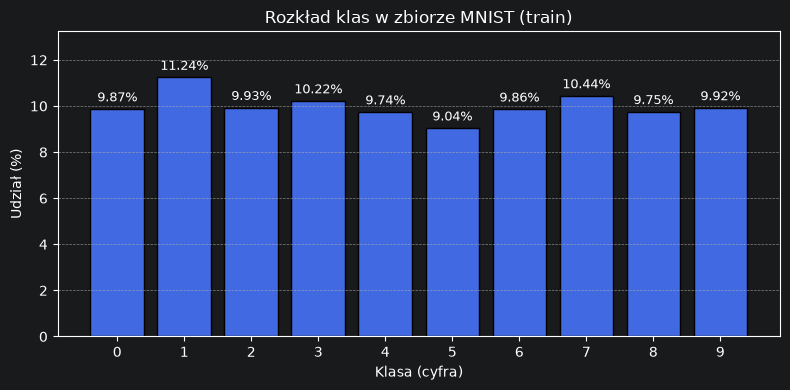

In [4]:
classes, counts = np.unique(y, return_counts=True)
percentages = (counts / len(y)) * 100

distribution_df = pd.DataFrame({
    'Liczba próbek': counts,
    'Udział (%)': np.round(percentages, 2)
}, index=pd.Index(classes, name='Klasa'))


plt.figure(figsize=(8, 4))
bars = plt.bar(distribution_df.index, distribution_df['Udział (%)'], color='royalblue', edgecolor='black')

plt.title('Rozkład klas w zbiorze MNIST (train)')
plt.xlabel('Klasa (cyfra)')
plt.ylabel('Udział (%)')
plt.xticks(distribution_df.index)
plt.ylim(0, max(distribution_df['Udział (%)']) + 2)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height + 0.2,
        f'{height:.2f}%',
        ha='center',
        va='bottom',
        fontsize=9
    )

plt.tight_layout()
save = Path(project_root) / "data/mnist/train" / "rozklad-klas.png"
plt.savefig(save, dpi=300, bbox_inches='tight')
plt.show()

In [3]:
X[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  

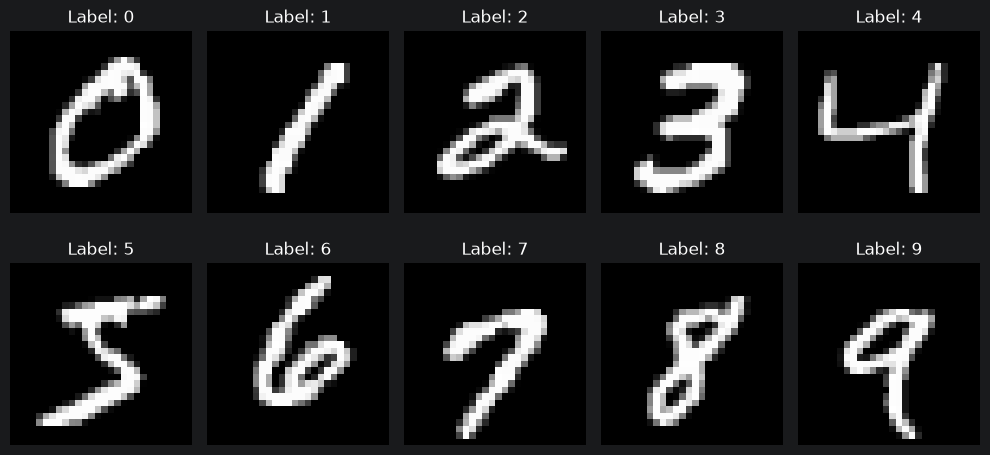

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.flatten()

for digit in range(10):
    idx = np.where(y == digit)[0][0]
    axes[digit].imshow(X[idx], cmap='gray')
    axes[digit].set_title(f"Label: {y[idx]}")
    axes[digit].axis('off')

plt.tight_layout()
plt.show()

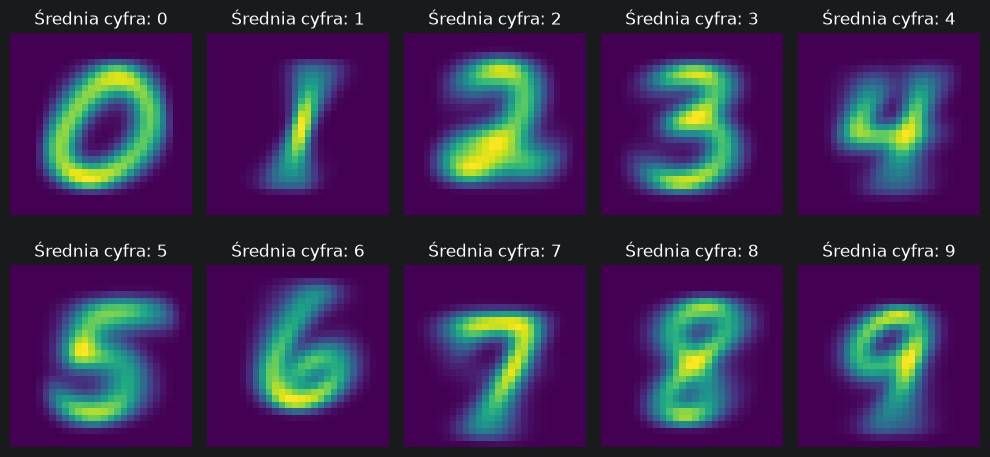

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
axes = axes.flatten()

for digit in range(10):
    mean_digit = X[y == digit].mean(axis=0)
    axes[digit].imshow(mean_digit, cmap='viridis')
    axes[digit].set_title(f"Średnia cyfra: {digit}")
    axes[digit].axis('off')

plt.tight_layout()
plt.show()

In [7]:
variance_map = X.var(axis=0)
dead_pixels = np.sum(variance_map == 0)

print(f"Liczba pikseli o zerowej wariancji (zawsze 0): {dead_pixels} / 784")

Liczba pikseli o zerowej wariancji (zawsze 0): 67 / 784


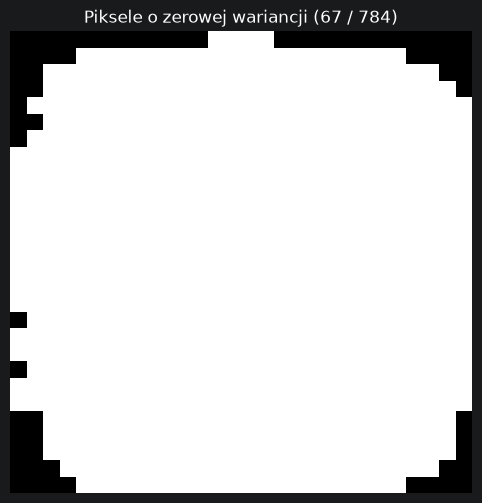

In [9]:
variance_map = X.var(axis=0)
zero_variance_mask = (variance_map == 0)

plt.figure(figsize=(6, 6))
plt.imshow(zero_variance_mask, cmap='gray_r')
plt.title(f'Piksele o zerowej wariancji ({zero_variance_mask.sum()} / {zero_variance_mask.size})')
plt.axis('off')

plt.show()

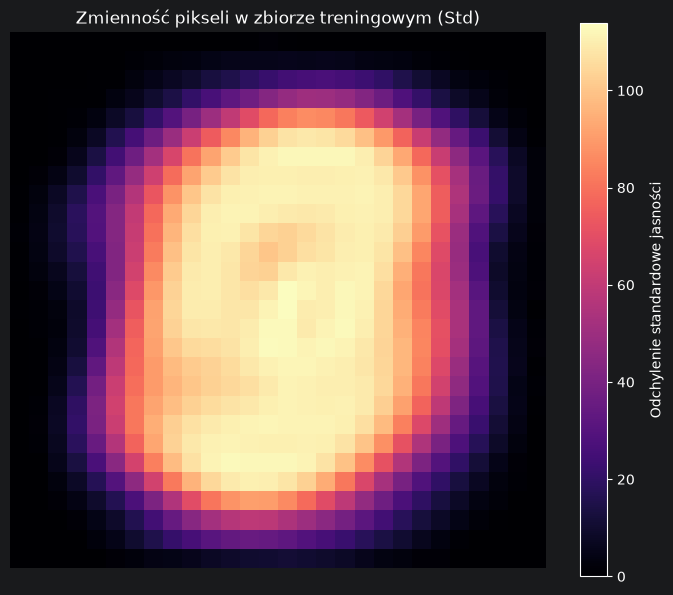

In [10]:
import matplotlib.pyplot as plt

std_map = X.std(axis=0)

plt.figure(figsize=(7, 6))
im = plt.imshow(std_map, cmap='magma')
plt.colorbar(im, label='Odchylenie standardowe jasności')
plt.title('Zmienność pikseli w zbiorze treningowym (Std)')
plt.axis('off')
plt.tight_layout()
plt.show()